# 14 — Full Market Scan And Watchlist

Notebook nay da chuyen sang workflow moi:

- universe full market duoc quet nhe tu notebook 02
- notebook 02 se tu dong tao `auto top 10 watchlist`
- notebook 14 uu tien scan sau tren `auto top 10` nay, nhung van cho phep ban override thu cong

Muc tieu: khong tinh toan nang tren toan bo thi truong neu chua can thiet.


In [3]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path

def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")

project_root = find_project_root()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)


Project root: /Users/jamesb/Desktop/vietnam-quant-research


In [4]:
# Cell: Import Screening Modules
import importlib
import inspect

import pandas as pd

import src.reporting.chart_factory as chart_factory
import src.screening.stealth_accumulation as stealth_accumulation
from src.data.loaders import read_parquet, save_parquet
from src.screening.light_market_scan import load_auto_watchlist_symbols

chart_factory = importlib.reload(chart_factory)
stealth_accumulation = importlib.reload(stealth_accumulation)

load_screen_config = stealth_accumulation.load_screen_config
run_stealth_accumulation_screen = stealth_accumulation.run_stealth_accumulation_screen
latest_screen_snapshot = stealth_accumulation.latest_screen_snapshot
compare_screen_backtests = stealth_accumulation.compare_screen_backtests
entropy_regime_chart = chart_factory.entropy_regime_chart
screen_score_bar_chart = chart_factory.screen_score_bar_chart
stage_distribution_chart = chart_factory.stage_distribution_chart
screen_history_chart = chart_factory.screen_history_chart
sector_distribution_chart = chart_factory.sector_distribution_chart
backtest_horizon_chart = chart_factory.backtest_horizon_chart
backtest_path_chart = chart_factory.backtest_path_chart

print(inspect.signature(run_stealth_accumulation_screen))


(price_df: 'pd.DataFrame', volatility_df: 'pd.DataFrame | None' = None, distribution_df: 'pd.DataFrame | None' = None, market_df: 'pd.DataFrame | None' = None, config: 'dict[str, Any] | None' = None) -> 'pd.DataFrame'


In [5]:
# Cell: Load Config And Market Data
config_path = "config/screens/stealth_accumulation.yaml"
screen_config = load_screen_config(config_path)

price_df = read_parquet("data/processed/clean_daily_ohlcv.parquet")
features_df = read_parquet("data/processed/stock_features.parquet")
volatility_df = features_df
distribution_df = features_df
market_df = read_parquet("data/processed/market_features.parquet")

coverage = {
    "symbols_in_price_data": int(price_df["symbol"].nunique()) if not price_df.empty else 0,
    "rows_in_price_data": int(len(price_df)),
    "date_min": str(pd.to_datetime(price_df["date"]).min().date()) if not price_df.empty else None,
    "date_max": str(pd.to_datetime(price_df["date"]).max().date()) if not price_df.empty else None,
    "market_feature_rows": int(len(market_df)),
    "has_market_entropy": bool("market_entropy_21d" in market_df.columns),
}
display(pd.DataFrame([coverage]).T.rename(columns={0: "value"}))
if not market_df.empty:
    display(market_df.sort_values("date").tail(3)[[col for col in ["date", "market_regime", "market_entropy_21d", "market_entropy_regime", "market_entropy_shift"] if col in market_df.columns]])


,value
symbols_in_price_data,567
rows_in_price_data,189047
date_min,2020-01-02
date_max,2026-06-30
market_feature_rows,1617
has_market_entropy,True


,date,market_regime,market_entropy_21d,market_entropy_regime,market_entropy_shift
1614,2026-06-25,Risk-off,0.804740,Chaotic,Stable
1615,2026-06-26,Risk-off,0.783968,Chaotic,Stable
1616,2026-06-29,Risk-off,0.804740,Chaotic,Stable


In [6]:
# Cell: Set Optional Universe Filters
selected_symbols = []
selected_markets = []

# Vi du: selected_symbols = ["MBB", "SSI", "VCI"]
# Vi du: selected_markets = ["HOSE"]

if selected_symbols:
    screen_config["universe"]["symbols"] = selected_symbols
if selected_markets:
    screen_config["universe"]["markets"] = selected_markets

pd.DataFrame([
    {
        "selected_symbols_count": len(selected_symbols),
        "selected_markets_count": len(selected_markets),
    }
])


,selected_symbols_count,selected_markets_count
0,0,0


In [7]:
# Cell: Validate Scan Universe
scan_input = price_df.copy()
scan_mode = "full_local_market_dataset"
if selected_symbols:
    symbol_set = {str(symbol).upper() for symbol in selected_symbols}
    scan_input = scan_input[scan_input["symbol"].astype(str).str.upper().isin(symbol_set)].copy()
    scan_mode = "custom_symbol_subset"
if selected_markets and "market" in scan_input.columns:
    market_set = {str(market).upper() for market in selected_markets}
    scan_input = scan_input[scan_input["market"].astype(str).str.upper().isin(market_set)].copy()
    scan_mode = "custom_market_subset" if not selected_symbols else "custom_symbol_and_market_subset"

scan_summary = {
    "scan_mode": scan_mode,
    "raw_symbols_in_dataset": int(price_df["symbol"].nunique()) if not price_df.empty else 0,
    "effective_symbols_to_scan": int(scan_input["symbol"].nunique()) if not scan_input.empty else 0,
    "effective_rows_to_scan": int(len(scan_input)),
    "selected_symbol_count": len(selected_symbols),
    "selected_market_count": len(selected_markets),
}
display(pd.DataFrame([scan_summary]))
if not scan_input.empty and "market" in scan_input.columns:
    display(scan_input.groupby("market")["symbol"].nunique().rename("symbols").reset_index())


,scan_mode,raw_symbols_in_dataset,effective_symbols_to_scan,effective_rows_to_scan,selected_symbol_count,selected_market_count
0,full_local_market_dataset,567,567,189047,0,0


,market,symbols
0,HNX,42
1,HOSE,463
2,UPCOM,75


In [8]:
# Cell: Run Full Market Stealth Scan
screen_df = run_stealth_accumulation_screen(
    price_df=price_df,
    volatility_df=volatility_df,
    distribution_df=distribution_df,
    market_df=market_df,
    config=screen_config,
)

screen_df[[
    "symbol",
    "date",
    "accumulation_score",
    "breakout_quality_score",
    "fakeout_risk_score",
    "net_accumulation_score",
    "accumulation_stage",
    "screen_pass",
    "watchlist_flag",
]].tail(10)


,symbol,date,accumulation_score,breakout_quality_score,fakeout_risk_score,net_accumulation_score,accumulation_stage,screen_pass,watchlist_flag
172330,HQC,2026-06-30,20.877489,22.121528,14.930568,37.236485,No Structure,False,False
172331,BSR,2026-06-30,24.240850,28.621528,29.407515,36.923928,No Structure,False,False
172332,HSL,2026-06-30,28.439396,34.102049,45.600463,36.345094,No Structure,False,False
172333,LPB,2026-06-30,25.753419,39.857017,47.332200,36.007914,No Structure,False,False
172334,PLX,2026-06-30,23.491787,28.156250,31.656075,35.870937,No Structure,False,False
172335,NVL,2026-06-30,24.741081,26.197917,36.406431,34.818412,No Structure,False,False
172336,KSF,2026-06-30,19.596978,20.432169,27.074474,33.137913,No Structure,False,False
172337,THD,2026-06-30,20.217786,30.059028,47.898396,30.649051,No Structure,False,False
172338,IDJ,2026-06-30,15.090545,17.045139,33.527201,28.424757,No Structure,False,False
172339,TCO,2026-06-30,8.511036,12.565972,41.593264,21.998695,No Structure,False,False


In [9]:
# Cell: Review Raw Leaders
top_n = int(screen_config["output"]["top_n"])
sector_cfg = screen_config["sector"]

latest_leaders = latest_screen_snapshot(screen_df, top_n=top_n, only_watchlist=False)
sector_leaders = latest_screen_snapshot(
    screen_df,
    top_n=top_n,
    only_watchlist=False,
    sector_aware=True,
    max_names_per_sector=sector_cfg["max_names_per_sector"],
    sector_col=sector_cfg["column"],
    unknown_sector=sector_cfg["unknown_label"],
)

review_cols = [
    "symbol",
    "sector",
    "date",
    "accumulation_score",
    "breakout_quality_score",
    "fakeout_risk_score",
    "net_accumulation_score",
    "accumulation_stage",
    "screen_pass",
    "watchlist_flag",
]

display(latest_leaders[review_cols])
display(sector_leaders[review_cols + ["selection_rank"]] if "selection_rank" in sector_leaders.columns else sector_leaders[review_cols])


,symbol,sector,date,accumulation_score,breakout_quality_score,fakeout_risk_score,net_accumulation_score,accumulation_stage,screen_pass,watchlist_flag
0,SAB,Unclassified,2026-06-30,66.387109,58.487715,6.000000,71.315483,Stage S: Tight Squeeze,True,True
1,BID,Unclassified,2026-06-30,63.109782,61.798019,19.333333,67.171062,Stage S: Tight Squeeze,True,True
2,VPI,Unclassified,2026-06-30,55.017637,68.872668,15.870130,65.759453,Stage S: Tight Squeeze,True,True


,symbol,sector,date,accumulation_score,breakout_quality_score,fakeout_risk_score,net_accumulation_score,accumulation_stage,screen_pass,watchlist_flag,selection_rank
0,SAB,Unclassified,2026-06-30,66.387109,58.487715,6.000000,71.315483,Stage S: Tight Squeeze,True,True,1
1,BID,Unclassified,2026-06-30,63.109782,61.798019,19.333333,67.171062,Stage S: Tight Squeeze,True,True,2


In [10]:
# Cell: Review Watchlist Candidates
latest_watchlist = latest_screen_snapshot(screen_df, top_n=top_n, only_watchlist=True)
sector_watchlist = latest_screen_snapshot(
    screen_df,
    top_n=top_n,
    only_watchlist=True,
    sector_aware=True,
    max_names_per_sector=sector_cfg["max_names_per_sector"],
    sector_col=sector_cfg["column"],
    unknown_sector=sector_cfg["unknown_label"],
)

display(latest_watchlist[review_cols])
display(sector_watchlist[review_cols + ["selection_rank"]] if not sector_watchlist.empty and "selection_rank" in sector_watchlist.columns else sector_watchlist.head(0))


,symbol,sector,date,accumulation_score,breakout_quality_score,fakeout_risk_score,net_accumulation_score,accumulation_stage,screen_pass,watchlist_flag
0,SAB,Unclassified,2026-06-30,66.387109,58.487715,6.000000,71.315483,Stage S: Tight Squeeze,True,True
1,BID,Unclassified,2026-06-30,63.109782,61.798019,19.333333,67.171062,Stage S: Tight Squeeze,True,True
2,VPI,Unclassified,2026-06-30,55.017637,68.872668,15.870130,65.759453,Stage S: Tight Squeeze,True,True


,symbol,sector,date,accumulation_score,breakout_quality_score,fakeout_risk_score,net_accumulation_score,accumulation_stage,screen_pass,watchlist_flag,selection_rank
0,SAB,Unclassified,2026-06-30,66.387109,58.487715,6.000000,71.315483,Stage S: Tight Squeeze,True,True,1
1,BID,Unclassified,2026-06-30,63.109782,61.798019,19.333333,67.171062,Stage S: Tight Squeeze,True,True,2


In [11]:
# Cell: Visualize Scan Diagnostics
display(screen_score_bar_chart(latest_leaders, top_n=top_n, title="Full Market Stealth Leaders"))
display(screen_score_bar_chart(latest_watchlist if not latest_watchlist.empty else latest_leaders, top_n=top_n, title="Actionable Stealth Watchlist"))

latest_date = screen_df["date"].max()
display(stage_distribution_chart(screen_df[screen_df["date"] == latest_date], title="Latest Stage Distribution"))
display(sector_distribution_chart(sector_leaders, title="Sector Mix Of Sector-Aware Leaders"))


In [12]:
# Cell: Inspect Symbol History
focus_candidates = []
if not sector_watchlist.empty:
    focus_candidates.append(sector_watchlist["symbol"].iloc[0])
if not sector_leaders.empty:
    focus_candidates.append(sector_leaders["symbol"].iloc[0])
if not latest_leaders.empty:
    focus_candidates.append(latest_leaders["symbol"].iloc[0])
focus_symbol = focus_candidates[0] if focus_candidates else None

history_cols = [
    "date",
    "symbol",
    "sector",
    "accumulation_score",
    "breakout_quality_score",
    "fakeout_risk_score",
    "net_accumulation_score",
    "accumulation_stage",
    "distance_to_pivot",
    "volume_ratio_5_20",
    "relative_strength_20d",
]

if focus_symbol is None:
    print("Chua co symbol nao vuot qua bo loc hien tai de inspect history")
else:
    display(screen_df[screen_df["symbol"] == focus_symbol][history_cols].tail(20))
    screen_history_chart(screen_df, symbol=focus_symbol, title="Stealth Accumulation Score History")


,date,symbol,sector,accumulation_score,breakout_quality_score,fakeout_risk_score,net_accumulation_score,accumulation_stage,distance_to_pivot,volume_ratio_5_20,relative_strength_20d
164504,2026-06-03,SAB,Unclassified,66.767460,53.549311,5.252525,70.457927,No Structure,-0.037487,0.694117,0.020167
164927,2026-06-04,SAB,Unclassified,69.551123,57.010196,0.000000,74.028110,No Structure,-0.031408,0.699684,0.048923
165367,2026-06-05,SAB,Unclassified,67.637981,54.874149,3.076923,71.768297,No Structure,-0.031408,0.725061,0.053213
165819,2026-06-08,SAB,Unclassified,69.209381,45.540873,13.333333,67.656576,No Structure,-0.047619,0.872336,0.014709
166266,2026-06-09,SAB,Unclassified,70.674557,52.555674,11.818182,70.521652,No Structure,-0.044580,0.808249,0.017686
166701,2026-06-10,SAB,Unclassified,71.535422,55.475810,0.000000,74.636663,No Structure,-0.036474,0.718846,0.043675
167138,2026-06-11,SAB,Unclassified,76.750047,64.053822,1.558442,78.998869,No Structure,-0.015198,1.012074,0.073491
167599,2026-06-12,SAB,Unclassified,74.453099,65.494671,20.000000,73.600217,No Structure,-0.015198,1.158655,0.038834
168048,2026-06-15,SAB,Unclassified,75.106647,67.305334,14.387352,75.782819,Stage S: Tight Squeeze,-0.017224,1.094201,0.040371
168510,2026-06-16,SAB,Unclassified,68.201894,70.639921,5.309281,75.433607,Stage C: Valid Expansion,-0.005066,1.363462,0.035069


,portfolio_type,holding_period_days,observations,avg_forward_return,avg_net_forward_return,avg_trading_cost,avg_signal_to_entry_gap,avg_benchmark_return,avg_excess_return,avg_net_excess_return,...,excess_hit_rate,net_excess_hit_rate,avg_selection_count,volatility_of_avg_returns,volatility_of_avg_net_returns,sharpe_like,net_sharpe_like,information_ratio_like,net_information_ratio_like,benchmark_source
0,raw,5,958,0.000887,0.000887,0.0,0.002567,0.001565,-0.000614,-0.000614,...,0.419624,0.419624,3.239040,0.050550,0.050550,0.124583,0.124583,-0.100186,-0.100186,benchmark_vnindex.parquet
1,raw,10,953,0.002254,0.002254,0.0,0.002575,0.003225,-0.000959,-0.000959,...,0.433368,0.433368,3.229801,0.073940,0.073940,0.153028,0.153028,-0.076826,-0.076826,benchmark_vnindex.parquet
2,raw,20,943,-0.024960,-0.024960,0.0,0.002604,0.008231,-0.033238,-0.033238,...,0.344645,0.344645,3.211029,0.113619,0.113619,-0.779805,-0.779805,-1.140487,-1.140487,benchmark_vnindex.parquet
3,sector_aware,5,958,0.000938,0.000938,0.0,0.002342,0.001565,-0.000648,-0.000648,...,0.412317,0.412317,2.281837,0.049772,0.049772,0.133779,0.133779,-0.107421,-0.107421,benchmark_vnindex.parquet
4,sector_aware,10,953,0.003188,0.003188,0.0,0.002344,0.003225,0.000007,0.000007,...,0.439664,0.439664,2.283316,0.071537,0.071537,0.223734,0.223734,0.000571,0.000571,benchmark_vnindex.parquet
5,sector_aware,20,943,-0.019372,-0.019372,0.0,0.002373,0.008231,-0.027494,-0.027494,...,0.365854,0.365854,2.286320,0.110760,0.110760,-0.620824,-0.620824,-0.975428,-0.975428,benchmark_vnindex.parquet


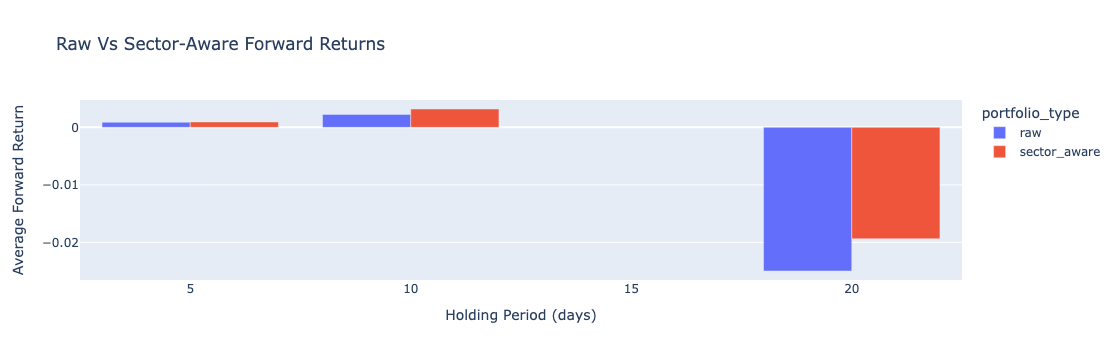

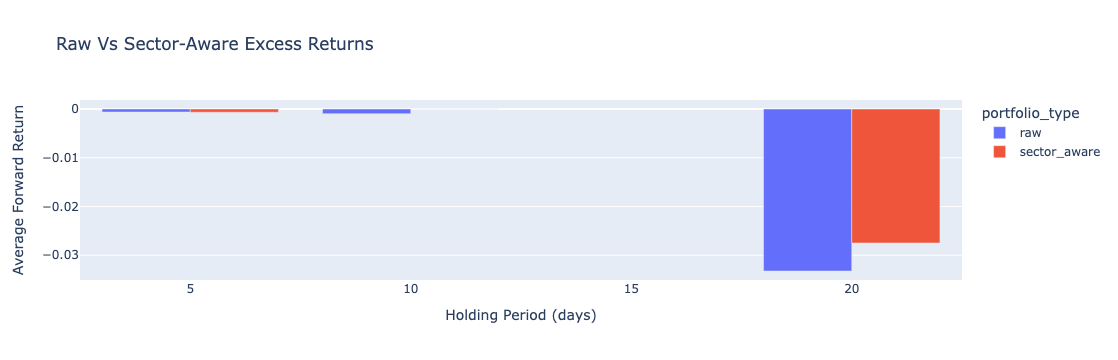

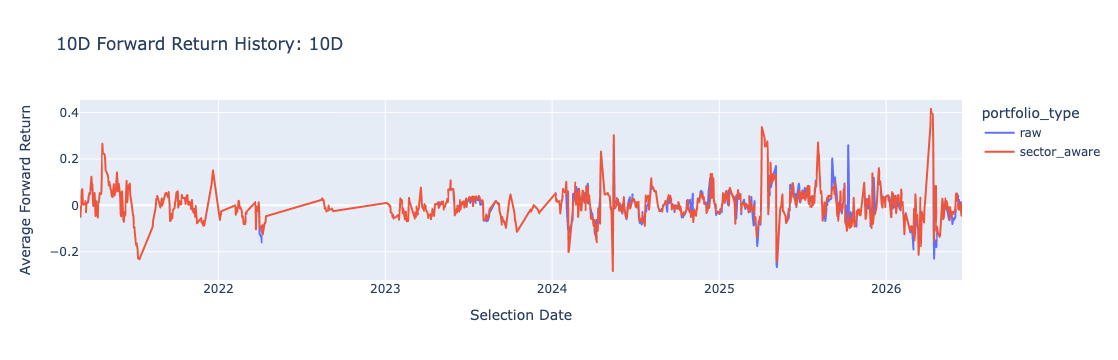

In [13]:
# Cell: Backtest Screener Quality
backtest_cfg = screen_config["backtest"]
backtest_results = compare_screen_backtests(
    screen_df,
    top_n=backtest_cfg["top_n"],
    holding_periods=backtest_cfg["holding_periods"],
    only_watchlist=backtest_cfg["only_watchlist"],
    max_names_per_sector=sector_cfg["max_names_per_sector"],
    sector_col=sector_cfg["column"],
    unknown_sector=sector_cfg["unknown_label"],
    benchmark_symbol=backtest_cfg.get("benchmark_symbol", "VNINDEX"),
    benchmark_path=backtest_cfg.get("benchmark_path"),
)

display(backtest_results["summary"])
display(backtest_horizon_chart(backtest_results["summary"], title="Raw Vs Sector-Aware Forward Returns"))
display(backtest_horizon_chart(backtest_results["summary"], value_col="avg_excess_return", title="Raw Vs Sector-Aware Excess Returns"))
display(backtest_path_chart(backtest_results["by_date"], holding_period=10, title="10D Forward Return History"))


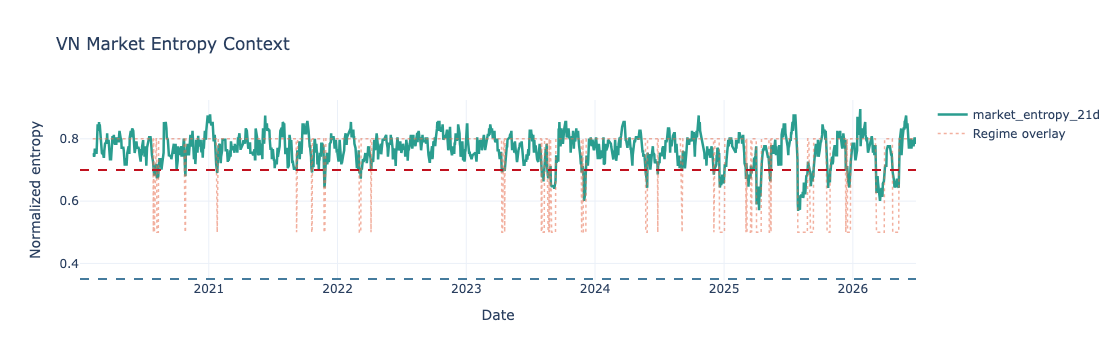

,date,market_regime,market_entropy_21d,market_entropy_63d,market_entropy_regime,market_entropy_shift,advance_ratio
1607,2026-06-16,Risk-off,0.768288,0.710323,Chaotic,Stable,0.478723
1608,2026-06-17,Risk-off,0.776128,0.710323,Chaotic,Stable,0.431624
1609,2026-06-18,Risk-off,0.776128,0.711834,Chaotic,Stable,0.270968
1610,2026-06-19,Risk-off,0.796900,0.709656,Chaotic,Stable,0.214133
1611,2026-06-22,Risk-off,0.776128,0.699388,Chaotic,Stable,0.330472
1612,2026-06-23,Risk-off,0.804740,0.755755,Chaotic,Stable,0.239224
1613,2026-06-24,Risk-off,0.804740,0.739018,Chaotic,Stable,0.313283
1614,2026-06-25,Risk-off,0.804740,0.723338,Chaotic,Stable,0.354430
1615,2026-06-26,Risk-off,0.783968,0.721827,Chaotic,Stable,0.341880
1616,2026-06-29,Risk-off,0.804740,0.704219,Chaotic,Stable,0.490826


In [14]:
# Cell: Review Market Entropy Context
if market_df.empty or "market_entropy_21d" not in market_df.columns:
    print("Market entropy chua san sang. Chay notebook 06 de build them entropy profile cho market.")
else:
    display(entropy_regime_chart(market_df.sort_values("date"), entropy_col="market_entropy_21d", regime_col="market_entropy_regime", title="VN Market Entropy Context"))
    display(market_df.sort_values("date").tail(10)[[col for col in ["date", "market_regime", "market_entropy_21d", "market_entropy_63d", "market_entropy_regime", "market_entropy_shift", "advance_ratio"] if col in market_df.columns]])


In [15]:
# Cell: Save Scan Outputs
save_parquet(screen_df, "data/signals/stealth_accumulation_history.parquet")
save_parquet(latest_leaders, "data/signals/stealth_accumulation_latest.parquet")
save_parquet(latest_watchlist, "data/signals/stealth_accumulation_watchlist.parquet")
save_parquet(sector_leaders, "data/signals/stealth_accumulation_sector_latest.parquet")
save_parquet(sector_watchlist, "data/signals/stealth_accumulation_sector_watchlist.parquet")
save_parquet(backtest_results["summary"], "data/signals/stealth_accumulation_backtest_summary.parquet")
save_parquet(backtest_results["by_date"], "data/signals/stealth_accumulation_backtest_by_date.parquet")
save_parquet(backtest_results["selections"], "data/signals/stealth_accumulation_backtest_selections.parquet")

print("Saved stealth accumulation outputs to data/signals")


Saved stealth accumulation outputs to data/signals
